# Rain Prediction — Spatial neighbour features (EXP-006)

The last untested same-target signal axis. EXP-005 exhausted same-station information
(instantaneous + history + moisture). Weather advects across space, so a **neighbouring
station's** recent conditions may carry information the home station's own record does not.

Les 49 `Location` sont géocodées **dans le notebook** (aucun appel réseau) ; un graphe des
**K=3 plus proches voisins** (distance orthodromique) est construit, et chaque couple
station-jour reçoit les agrégats des observations de ses voisins — **même jour** (`_t`, cohérent
avec les features de base du jour `t`) et **veille** (`_t1`, strictement passé). Tout est bâti
sur **`weatherAUS_trend_grouped.csv`** (frame pré-imputation, NaN des voisins ignorés via
`mean` qui saute les NaN), donc aucune valeur reconstruite par MICE n'entre dans un agrégat.

Ablation en 3 temps **base → base+temporal → base+temporal+spatial** sur **les deux** splits,
comme EXP-005. Le split chronologique est celui du pipeline
(`weatherAUS_{X,y}_{train,test}.csv`). Logs -> `SPATIAL_result.txt`, figures `spatial_*`,
modèles `joblib` dans `../../models/`.


## 1. Setup, imports, constants

In [2]:
import os, sys, warnings
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, GroupKFold, GroupShuffleSplit
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    roc_curve, precision_recall_curve, auc,
)
import xgboost as xgb
from xgboost import XGBClassifier
warnings.filterwarnings('ignore', category=UserWarning, module='xgboost')

RANDOM_STATE = 42
TEST_CUTOFF = pd.Timestamp('2016-01-01')

def _gpu_available():
    try:
        d = xgb.DMatrix(np.zeros((8, 2)), label=np.zeros(8))
        xgb.train({'device': 'cuda', 'tree_method': 'hist'}, d, num_boost_round=1)
        return True
    except Exception as e:
        print(f'CUDA probe failed ({type(e).__name__}); CPU fallback.'); return False

USE_GPU = _gpu_available()
DEVICE = 'cuda' if USE_GPU else 'cpu'
SEARCH_N_JOBS = 1 if USE_GPU else -1
XGB_KW = dict(tree_method='hist', device=DEVICE, eval_metric='logloss',
              random_state=RANDOM_STATE, n_jobs=-1)
def make_xgb(**ov):
    p = dict(XGB_KW); p.update(ov); return XGBClassifier(**p)

V2_PARAMS = dict(max_depth=6, min_child_weight=10, gamma=2.0, reg_lambda=20, reg_alpha=0.5,
                 learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, n_estimators=800)
print(f'xgboost {xgb.__version__} | device: {DEVICE}')

xgboost 3.4.0 | device: cuda


### Output setup

In [3]:
os.makedirs('figures', exist_ok=True)
_PATH = 'SPATIAL_result.txt'
_FILE = open(_PATH, 'w', encoding='utf-8')
class _Tee:
    def __init__(self, *s): self._s = s
    def write(self, d):
        for s in self._s: s.write(d)
    def flush(self):
        for s in self._s: s.flush()
    def isatty(self): return False
_ORIG = sys.stdout; sys.stdout = _Tee(_ORIG, _FILE)
print('# Spatial neighbour features (both splits) — numerical outputs')
print(f'# Generated: {datetime.now().strftime("%Y-%m-%d %H:%M:%S")}')
def log_section(t):
    print('\n' + '=' * 72 + '\n' + t + '\n' + '=' * 72)
def save_fig(name, fig=None):
    fig = fig or plt.gcf(); p = f'figures/{name}.png'
    fig.savefig(p, dpi=150, bbox_inches='tight'); print(f'  [saved {p}]')

# --- Sérialisation des modèles ---------------------------------------------
# Chaque étape du notebook est enregistrée dans <repo>/models sous forme d'un
# dict joblib : le modèle + les métadonnées nécessaires pour le rejouer.
MODEL_DIR = os.environ.get('WEATHER_MODEL_DIR', '../../models')
os.makedirs(MODEL_DIR, exist_ok=True)
NOTEBOOK = 'EXP-006_XGBoost_spatial'

def save_model(obj, name, **meta):
    """Sauvegarde `obj` dans MODEL_DIR/<name>.joblib avec ses métadonnées."""
    path = f'{MODEL_DIR}/{name}.joblib'
    joblib.dump({'model': obj,
                 'notebook': NOTEBOOK,
                 'created_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
                 **meta}, path)
    print(f'  [saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)]')

# Spatial neighbour features (both splits) — numerical outputs
# Generated: 2026-08-11 12:58:13

2. Data loading (sorties du pipeline)
X_train (113506, 29) | X_test (25314, 29)
Train 2007-11-01 -> 2015-12-31 | Test 2016-01-01 -> 2017-06-25
Stations : 49 | pluie train 21.9574% / test 22.6950%
Pré-imputation : 138,820 lignes x 27 colonnes (292,371 NaN conservés)
<xml><var name="_dummy_ipython_val"  />
<var name="_dummy_special_var"  />
<var name="DATA_DIR" type="str" qualifier="builtins" value="../../data" />
<var name="DEVICE" type="str" qualifier="builtins" value="cuda" />
<var name="GroupKFold" type="ABCMeta" qualifier="abc" value="%3Cclass %27sklearn.model_selection._split.GroupKFold%27&gt;" isContainer="True" />
<var name="GroupShuffleSplit" type="ABCMeta" qualifier="abc" value="%3Cclass %27sklearn.model_selection._split.GroupShuffleSplit%27&gt;" isContainer="True" />
<var name="IN_COLAB" type="bool" qualifier="builtins" value="True" />
<var name="MODEL_DIR" type="str" qualifier="bu

## 2. Chargement — frame pré-imputation + matrices du pipeline

In [4]:
log_section('2. Data loading (sorties du pipeline)')

# Sorties du pipeline, dans <repo>/data :
#   3.preprocessing_trend_group.ipynb -> weatherAUS_trend_grouped.csv
#   4_preprocessing_imputation.ipynb  -> weatherAUS_MICE_cyclic.csv
#                                        weatherAUS_X_train.csv / weatherAUS_y_train.csv
#                                        weatherAUS_X_test.csv  / weatherAUS_y_test.csv
DATA_DIR = os.environ.get('WEATHER_DATA_DIR', '../../data')

# Matrices déjà splitées, encodées (LabelEncoder) et scalées (RobustScaler ajusté
# sur le train uniquement) par 4_preprocessing_imputation.ipynb.
X_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_train.csv')
X_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_X_test.csv')
y_train = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_train.csv').squeeze('columns').astype(int)
y_test  = pd.read_csv(f'{DATA_DIR}/weatherAUS_y_test.csv').squeeze('columns').astype(int)

# Index (Date, Location) aligné ligne à ligne sur X_train / X_test :
# weatherAUS_MICE_cyclic.csv est trié par Date et le pipeline y applique le même
# seuil TEST_CUTOFF, donc ses len(X_train) premières lignes SONT celles de X_train.
meta = pd.read_csv(f'{DATA_DIR}/weatherAUS_MICE_cyclic.csv',
                   usecols=['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm'], parse_dates=['Date'])
meta = meta[['Date', 'Location', 'Pressure9am', 'Pressure3pm', 'Temp9am', 'Temp3pm']]
assert len(meta) == len(X_train) + len(X_test), 'X_train/X_test ne recouvrent pas MICE_cyclic'
meta_train = meta.iloc[:len(X_train)].reset_index(drop=True)
meta_test  = meta.iloc[len(X_train):].reset_index(drop=True)
assert (meta_train['Date'] < TEST_CUTOFF).all(), 'lignes de train postérieures au seuil'
assert (meta_test['Date'] >= TEST_CUTOFF).all(), 'lignes de test antérieures au seuil'

print(f'X_train {X_train.shape} | X_test {X_test.shape}')
print(f'Train {meta_train["Date"].min().date()} -> {meta_train["Date"].max().date()} | '
      f'Test {meta_test["Date"].min().date()} -> {meta_test["Date"].max().date()}')
print(f'Stations : {meta["Location"].nunique()} | pluie train {y_train.mean():.4%} / test {y_test.mean():.4%}')

# Frame AVANT imputation (mêmes lignes, NaN d'origine conservés) : sert à
# reconstruire les features retardées / voisines sans réutiliser de valeur
# reconstruite par MICE.
pre = pd.read_csv(f'{DATA_DIR}/weatherAUS_trend_grouped.csv', parse_dates=['Date'])
assert len(pre) == len(meta), 'weatherAUS_trend_grouped.csv désaligné du pipeline'
print(f'Pré-imputation : {pre.shape[0]:,} lignes x {pre.shape[1]} colonnes '
      f'({pre.isna().sum().sum():,} NaN conservés)')

## 3. Base features (v2)

In [5]:
log_section('3. Base features (v2)')

# Features de tendance intra-journalière. Elles sont calculées sur les valeurs
# NON scalées de weatherAUS_MICE_cyclic.csv : une différence de colonnes déjà
# passées au RobustScaler (échelles distinctes) ne serait pas la même grandeur.
for X, m in ((X_train, meta_train), (X_test, meta_test)):
    X['Pressure_diff'] = (m['Pressure3pm'] - m['Pressure9am']).to_numpy()
    X['Temp_diff']     = (m['Temp3pm']     - m['Temp9am']).to_numpy()

# Le pipeline livre 29 colonnes. On retire les mêmes que l'étude LR pour que les
# expériences EXP-001..007 restent comparables entre elles :
DROP_COLS = [
    'WindGustDir', 'WindDir9am', 'WindDir3pm',  # labels encodés ; les sin/cos sont conservés
    'RainToday',                                # quasi-fuite (on donne déjà le reste de la journée)
    'Humidity9am',                              # on garde Humidity3pm (plus prédictive)
    'Month',                                    # redondant avec Date_sin / Date_cos
]
BASE_FEATURES = [c for c in X_train.columns if c not in DROP_COLS]

# Matrice complète dans l'ordre chronologique du pipeline : X_train puis X_test.
# Les blocs de features additionnels (temporel / spatial) viendront s'y coller.
X_all = pd.concat([X_train[BASE_FEATURES], X_test[BASE_FEATURES]], ignore_index=True)
y_all = pd.concat([y_train, y_test], ignore_index=True)
loc_all = meta['Location']
dates   = meta['Date']
N_TRAIN = len(X_train)

def align_to_pipeline(frame, cols):
    """Réaligne un bloc de features indexé par (Date, Location) sur l'ordre des
    lignes du pipeline. Les deux frames partagent la même clé unique, donc le
    réalignement est exact et ne peut pas dupliquer de ligne."""
    key = pd.MultiIndex.from_frame(frame[['Date', 'Location']])
    assert key.is_unique, 'clé (Date, Location) non unique dans le bloc de features'
    out = frame.set_axis(key)[cols].reindex(pd.MultiIndex.from_frame(meta[['Date', 'Location']]))
    return out.reset_index(drop=True)

print(f'BASE features: {len(BASE_FEATURES)} | X_all {X_all.shape}')

## 4. Temporal features (EXP-004 set, for the base+temporal comparison)

Identique à EXP-004, construit sur le frame pré-imputation.


In [6]:
log_section('4. Temporal features (frame pré-imputation, décalages arrière)')

# Toutes les features ci-dessous n'utilisent que les jours <= t-1 (pas d'info du jour
# même, pas de futur), construites par `Location` sur weatherAUS_trend_grouped.csv,
# c'est-à-dire AVANT l'imputation MICE : aucune valeur reconstruite ne peut remonter
# dans un lag. Les NaN qui en résultent (premiers jours / manquants d'origine) sont
# laissés tels quels — XGBoost les gère nativement et EXP-003 a montré que les
# imputer n'apporte rien.
pre_s = pre.sort_values(['Location', 'Date']).copy()
g = pre_s.groupby('Location', sort=False)

LAG_COLS = ['Humidity3pm','Pressure3pm','Rainfall','Cloud3pm','Sunshine','Temp3pm','WindGustSpeed']
feat = pd.DataFrame({'Date': pre_s['Date'].values, 'Location': pre_s['Location'].values})
for c in LAG_COLS:
    feat[f'{c}_lag1'] = g[c].shift(1).values

# multi-day, all strictly past (>= t-1)
feat['Pressure_3d_chg']  = (g['Pressure3pm'].shift(1) - g['Pressure3pm'].shift(4)).values
feat['Humidity_3d_mean'] = g['Humidity3pm'].apply(lambda s: s.shift(1).rolling(3).mean()).values
feat['Rainfall_3d_sum']  = g['Rainfall'].apply(lambda s: s.shift(1).rolling(3).sum()).values

# yesterday's rain flag + days since last rain (computed on the lagged flag -> strictly past)
rt = pre_s['RainToday'].astype(int)          # booléen dans le frame du pipeline
rt_lag = rt.groupby(pre_s['Location'], sort=False).shift(1)
feat['RainToday_lag1'] = rt_lag.values
def _days_since(s):
    out = np.empty(len(s)); cnt = 9999.0
    for i, v in enumerate(s.to_numpy()):
        out[i] = cnt
        cnt = 0.0 if v == 1 else (cnt + 1 if cnt < 9999 else 9999)
    return out
feat['days_since_rain'] = (
    rt_lag.fillna(0).groupby(pre_s['Location'], sort=False).transform(lambda s: _days_since(s)).values)

TEMPORAL_FEATURES = [c for c in feat.columns if c not in ('Date', 'Location')]
X_all[TEMPORAL_FEATURES] = align_to_pipeline(feat, TEMPORAL_FEATURES)
nan_share = X_all[TEMPORAL_FEATURES].isna().mean().mean()
print(f'Temporal features: {len(TEMPORAL_FEATURES)} -> {TEMPORAL_FEATURES}')
print(f'Mean NaN share across temporal features: {nan_share:.1%} (left for XGBoost native handling)')

## 5. Station geocoding + K-nearest-neighbour graph

Coordinates for all 49 stations are hardcoded (BoM station locations). A haversine distance matrix
gives each station its **K=3 nearest** neighbours.

In [7]:
log_section('5. Geocoding + neighbour graph')
COORDS = {
    'Adelaide': (-34.9285, 138.6007), 'Albany': (-35.0269, 117.8837),
    'Albury': (-36.0737, 146.9135), 'AliceSprings': (-23.6980, 133.8807),
    'BadgerysCreek': (-33.8829, 150.7609), 'Ballarat': (-37.5622, 143.8503),
    'Bendigo': (-36.7570, 144.2794), 'Brisbane': (-27.4698, 153.0251),
    'Cairns': (-16.9186, 145.7781), 'Canberra': (-35.2809, 149.1300),
    'Cobar': (-31.4958, 145.8389), 'CoffsHarbour': (-30.2986, 153.1094),
    'Dartmoor': (-37.9225, 141.2767), 'Darwin': (-12.4634, 130.8456),
    'GoldCoast': (-28.0167, 153.4000), 'Hobart': (-42.8821, 147.3272),
    'Katherine': (-14.4652, 132.2635), 'Launceston': (-41.4332, 147.1441),
    'Melbourne': (-37.8136, 144.9631), 'MelbourneAirport': (-37.6690, 144.8410),
    'Mildura': (-34.1855, 142.1625), 'Moree': (-29.4639, 149.8407),
    'MountGambier': (-37.8284, 140.7820), 'MountGinini': (-35.5294, 148.7723),
    'Newcastle': (-32.9283, 151.7817), 'Nhil': (-36.3333, 141.6500),
    'NorahHead': (-33.2833, 151.5667), 'NorfolkIsland': (-29.0408, 167.9547),
    'Nuriootpa': (-34.4700, 138.9960), 'PearceRAAF': (-31.6676, 116.0292),
    'Penrith': (-33.7507, 150.6877), 'Perth': (-31.9505, 115.8605),
    'PerthAirport': (-31.9385, 115.9672), 'Portland': (-38.3609, 141.6041),
    'Richmond': (-33.6000, 150.7667), 'Sale': (-38.1026, 147.0730),
    'SalmonGums': (-32.9815, 121.6438), 'Sydney': (-33.8688, 151.2093),
    'SydneyAirport': (-33.9399, 151.1753), 'Townsville': (-19.2590, 146.8169),
    'Tuggeranong': (-35.4244, 149.0888), 'Uluru': (-25.3444, 131.0369),
    'WaggaWagga': (-35.1082, 147.3598), 'Walpole': (-34.9777, 116.7338),
    'Watsonia': (-37.7100, 145.0830), 'Williamtown': (-32.8150, 151.8428),
    'Witchcliffe': (-34.0261, 115.1003), 'Wollongong': (-34.4278, 150.8931),
    'Woomera': (-31.1656, 136.8193),
}
data_locs = set(meta['Location'].unique())
missing = data_locs - set(COORDS)
assert not missing, f'missing coordinates for: {missing}'
stations = sorted(COORDS)

def haversine(a_lat, a_lon, b_lat, b_lon):
    R = 6371.0
    p1, p2 = np.radians(a_lat), np.radians(b_lat)
    dphi = np.radians(b_lat - a_lat); dl = np.radians(b_lon - a_lon)
    h = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dl/2)**2
    return 2 * R * np.arcsin(np.sqrt(h))

K = 3
neighbours, nearest_dist = {}, {}
for s in stations:
    ds = sorted((haversine(*COORDS[s], *COORDS[t]), t) for t in stations if t != s)
    neighbours[s] = [t for _, t in ds[:K]]
    nearest_dist[s] = ds[0][0]
print(f'K = {K} nearest neighbours. Examples:')
for s in ['Sydney', 'Perth', 'Darwin', 'NorfolkIsland']:
    print(f'  {s:14s} -> {neighbours[s]} (nearest {nearest_dist[s]:.0f} km)')

## 6. Spatial neighbour features (pré-imputation, same-day `_t` and yesterday `_t1`)

For each variable, pivot to a (Date × Station) grid, average across each station's 3 neighbours
(`mean` saute les NaN — voisins manquants ignorés), reindex to a complete daily calendar, and
optionally `shift(1)` for the strictly-past version. `_t` features mirror the home station's
same-day base features (available at forecast time); `_t1` are strictly past.


In [8]:
log_section('6. Spatial neighbour features')

# Construit sur le frame PRÉ-imputation : les NaN des voisins sont ignorés par la
# moyenne plutôt que remplacés par une valeur MICE.
pre2 = pre.assign(_RainToday=pre['RainToday'].astype(int))
full_dates = pd.date_range(pre['Date'].min(), pre['Date'].max(), freq='D')

def nbr_melt(var, lag, out_name):
    wide = (pre2.pivot_table(index='Date', columns='Location', values=var, dropna=False)
            .reindex(index=full_dates, columns=stations))
    nm = pd.DataFrame({s: wide[neighbours[s]].mean(axis=1) for s in stations}, index=wide.index)
    if lag:
        nm = nm.shift(1)
    nm.index.name = 'Date'
    return nm.reset_index().melt(id_vars='Date', var_name='Location', value_name=out_name)

specs = [('nbr_Rainfall_t', 'Rainfall', False), ('nbr_Rainfall_t1', 'Rainfall', True),
         ('nbr_Pressure3pm_t', 'Pressure3pm', False), ('nbr_Pressure3pm_t1', 'Pressure3pm', True),
         ('nbr_Humidity3pm_t', 'Humidity3pm', False), ('nbr_RainToday_t', '_RainToday', False)]
sfeat = meta[['Date', 'Location']].copy()
for out_name, var, lag in specs:
    sfeat = sfeat.merge(nbr_melt(var, lag, out_name), on=['Date', 'Location'], how='left')
sfeat['nearest_dist'] = sfeat['Location'].map(nearest_dist)

SPATIAL_FEATURES = [s[0] for s in specs] + ['nearest_dist']
X_all[SPATIAL_FEATURES] = align_to_pipeline(sfeat, SPATIAL_FEATURES)
print(f'Spatial features: {len(SPATIAL_FEATURES)} -> {SPATIAL_FEATURES}')
print('NaN share spatial %.1f%%' % (X_all[SPATIAL_FEATURES].isna().mean().mean() * 100))

## 7. Splits + 3 feature sets

In [9]:
log_section('7. Splits: chronologique (pipeline) + leave-stations-out')

# Chronologique : on REPREND le split du pipeline tel quel (les N_TRAIN premières
# lignes de X_all sont exactement X_train). Plus aucun re-tri n'est effectué ici,
# donc le bug de EXP-003 — masque trié par date appliqué à des features restées
# dans l'ordre d'origine, groupées par Location — ne peut plus se produire.
chrono_train = np.zeros(len(X_all), dtype=bool)
chrono_train[:N_TRAIN] = True
assert dates[chrono_train].max() < dates[~chrono_train].min(), 'split non chronologique !'
print('Chronological (pipeline):')
print(f'  train {chrono_train.sum():,} ({dates[chrono_train].min().date()}..{dates[chrono_train].max().date()})')
print(f'  test  {(~chrono_train).sum():,} ({dates[~chrono_train].min().date()}..{dates[~chrono_train].max().date()})')

# Leave-stations-out (split spatial délibéré, indépendant du pipeline)
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
sp_tr, sp_te = next(gss.split(X_all, y_all, groups=loc_all))
spatial_train = np.zeros(len(X_all), bool); spatial_train[sp_tr] = True
held = sorted(loc_all.iloc[sp_te].unique())
print(f'Leave-stations-out: {len(held)} held-out stations -> {held}')
print(f'  train {spatial_train.sum():,} | test {(~spatial_train).sum():,}')

SPLITS = {
    'chronological':      dict(train=chrono_train,  cv='time'),
    'leave-stations-out': dict(train=spatial_train, cv='group'),
}

ALL_FEATURES = BASE_FEATURES + TEMPORAL_FEATURES + SPATIAL_FEATURES
FEATURE_SETS = {
    'base':                  BASE_FEATURES,
    'base+temporal':         BASE_FEATURES + TEMPORAL_FEATURES,
    'base+temporal+spatial': ALL_FEATURES,
}
assert list(X_all.columns) == ALL_FEATURES

## 8. Helpers — PR-crossover threshold + evaluation

In [10]:
def pr_crossover_threshold(params, Xtr, ytr, cv, groups, grid=np.arange(0.10, 0.81, 0.01)):
    recs = []
    for tr, va in cv.split(Xtr, ytr, groups):
        m = make_xgb(**params); m.fit(Xtr.iloc[tr], ytr.iloc[tr])
        recs.append((ytr.iloc[va].values, m.predict_proba(Xtr.iloc[va])[:, 1]))
    best_t, best_d = 0.5, 1e9
    for t in grid:
        P = np.mean([precision_score(y, p >= t, zero_division=0) for y, p in recs])
        R = np.mean([recall_score(y, p >= t) for y, p in recs])
        F = np.mean([f1_score(y, p >= t) for y, p in recs])
        d = abs(P - F) + abs(F - R)
        if d < best_d: best_t, best_d = float(t), d
    return round(best_t, 2)

def evaluate(fs_name, cols, split_name, train_mask, cv_kind):
    Xtr = X_all.loc[train_mask, cols].reset_index(drop=True)
    Xte = X_all.loc[~train_mask, cols].reset_index(drop=True)
    ytr = y_all[train_mask].reset_index(drop=True)
    yte = y_all[~train_mask].reset_index(drop=True)
    pr = float(ytr.mean()); params = dict(V2_PARAMS); params['scale_pos_weight'] = (1 - pr) / pr
    if cv_kind == 'time':
        cv, groups = TimeSeriesSplit(n_splits=5), None
    else:
        cv, groups = GroupKFold(n_splits=5), loc_all[train_mask].reset_index(drop=True)
    t = pr_crossover_threshold(params, Xtr, ytr, cv, groups)
    m = make_xgb(**params); m.fit(Xtr, ytr)
    proba = m.predict_proba(Xte)[:, 1]; pred = (proba >= t).astype(int)
    p, r, _ = precision_recall_curve(yte, proba)
    row = dict(split=split_name, features=fs_name, n_feat=len(cols), threshold=t,
               F1=round(f1_score(yte, pred), 4), precision=round(precision_score(yte, pred), 4),
               recall=round(recall_score(yte, pred), 4),
               ROC_AUC=round(roc_auc_score(yte, proba), 4), PR_AUC=round(auc(r, p), 4))
    return m, row, proba, yte

## 9. Run 2 splits x 3 feature sets

In [11]:
log_section('9. Results — 2 splits x 3 feature sets')
results, store = [], {}
for sp_name, sp in SPLITS.items():
    for fs_name, cols in FEATURE_SETS.items():
        m, row, proba, yte = evaluate(fs_name, cols, sp_name, sp['train'], sp['cv'])
        results.append(row); store[(sp_name, fs_name)] = (m, proba, yte)
        print(f"  {sp_name:20s} {fs_name:24s} -> F1 {row['F1']:.4f}  ROC {row['ROC_AUC']:.4f}  PR {row['PR_AUC']:.4f}")
res = pd.DataFrame(results)
print('\nMaster table:')
print(res.to_string(index=False))

for (sp_name, fs_name), (m, _proba, _yte) in store.items():
    row = next(r for r in results if r['split'] == sp_name and r['features'] == fs_name)
    save_model(m, f"EXP-006_{sp_name.replace('-', '_')}__{fs_name.replace('+', '_')}",
               features=FEATURE_SETS[fs_name], split=sp_name, stage=f'{fs_name} / {sp_name}',
               params=V2_PARAMS, threshold=row['threshold'], metrics=row,
               K_neighbours=K, neighbours=neighbours)

## 10. ROC / PR curves per split

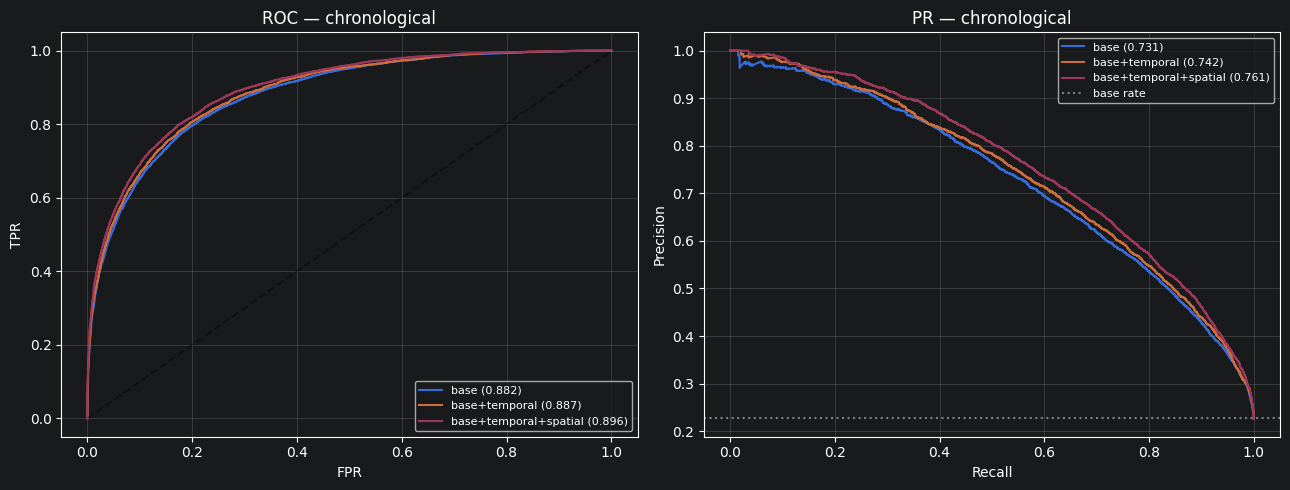

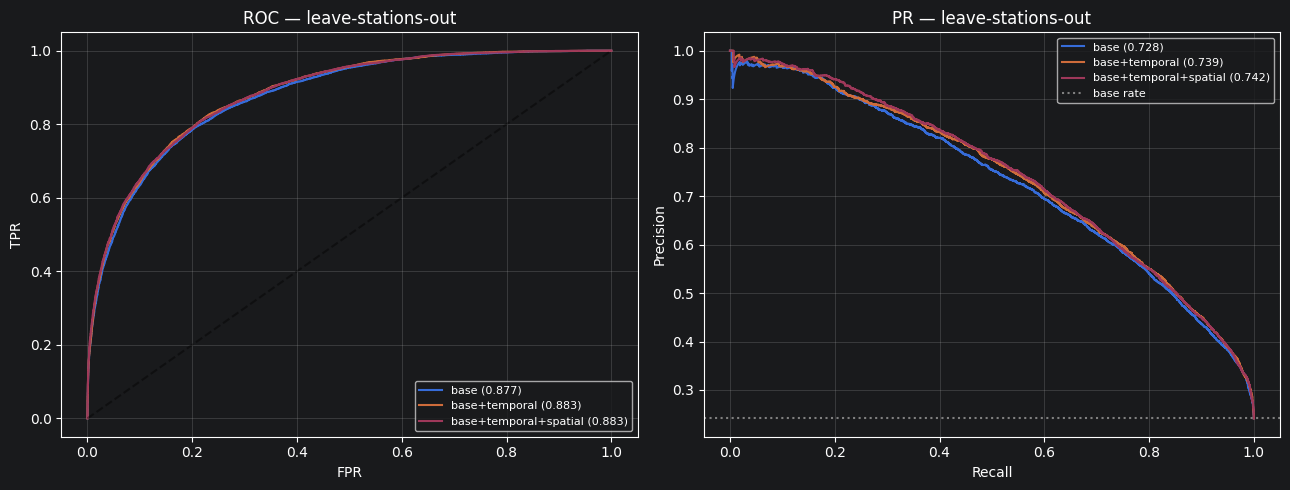

In [12]:
for sp_name in SPLITS:
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    for fs_name in FEATURE_SETS:
        _, proba, yte = store[(sp_name, fs_name)]
        fpr, tpr, _ = roc_curve(yte, proba)
        ax[0].plot(fpr, tpr, label=f'{fs_name} ({roc_auc_score(yte, proba):.3f})')
        p, r, _ = precision_recall_curve(yte, proba)
        ax[1].plot(r, p, label=f'{fs_name} ({auc(r, p):.3f})')
    ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.4); ax[0].set_title(f'ROC — {sp_name}')
    ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(loc='lower right', fontsize=8); ax[0].grid(alpha=0.3)
    ax[1].axhline(float(store[(sp_name, "base")][2].mean()), color='gray', ls=':', label='base rate')
    ax[1].set_title(f'PR — {sp_name}'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision')
    ax[1].legend(loc='upper right', fontsize=8); ax[1].grid(alpha=0.3)
    plt.tight_layout()
    save_fig(f'spatial_roc_pr_{sp_name.replace("-", "_")}', fig); plt.show()

## 11. Feature importance — spatial (red) / temporal (orange) / base (blue)

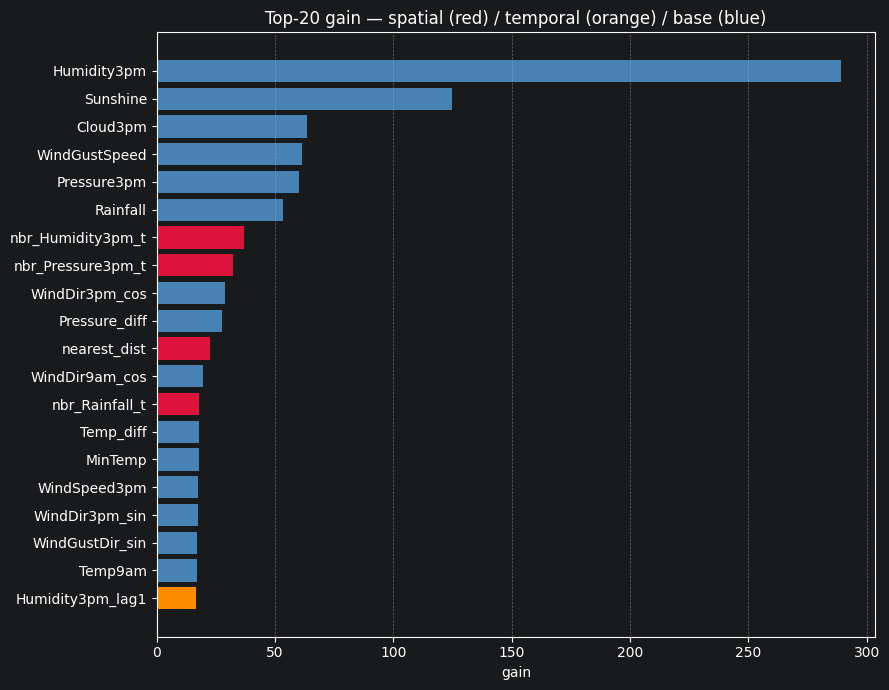

In [13]:
log_section('11. Importance (chronological, full feature set)')
m_full = store[('chronological', 'base+temporal+spatial')][0]
gain = m_full.get_booster().get_score(importance_type='gain')
def kind(f):
    if f in SPATIAL_FEATURES:  return 'spatial'
    if f in TEMPORAL_FEATURES: return 'temporal'
    return 'base'
imp = pd.DataFrame([(k, gain.get(k, 0.0), kind(k)) for k in ALL_FEATURES],
                   columns=['feature', 'gain', 'kind']).sort_values('gain', ascending=False).reset_index(drop=True)
print('Top 20 by gain (S=spatial, T=temporal):')
for _, r in imp.head(20).iterrows():
    tag = {'spatial': 'S', 'temporal': 'T', 'base': ' '}[r.kind]
    print(f'  {tag} {r.feature:20s} {r.gain:8.2f}')
print('\nSpatial features and their ranks:')
for f in SPATIAL_FEATURES:
    rank = int(imp.index[imp.feature == f][0]) + 1
    print(f'  {f:20s} rank {rank}/{len(imp)}  gain {float(imp.loc[imp.feature==f,"gain"].iloc[0]):.2f}')

cmap = {'spatial': 'crimson', 'temporal': 'darkorange', 'base': 'steelblue'}
fig, ax = plt.subplots(figsize=(9, 7))
top = imp.head(20)
ax.barh(top['feature'][::-1], top['gain'][::-1], color=[cmap[k] for k in top['kind']][::-1])
ax.set_xlabel('gain'); ax.set_title('Top-20 gain — spatial (red) / temporal (orange) / base (blue)')
ax.grid(axis='x', ls='--', alpha=0.5); plt.tight_layout()
save_fig('spatial_feature_importance', fig); plt.show()

## 12. Verdict — does spatial context add over temporal?

In [14]:
log_section('12. Verdict')
def row(sp, fs): return res[(res.split == sp) & (res.features == fs)].iloc[0]
for sp in SPLITS:
    b = row(sp, 'base'); t = row(sp, 'base+temporal'); s = row(sp, 'base+temporal+spatial')
    print(f'{sp}:')
    print(f'  base -> +temporal    dF1 {t.F1-b.F1:+.4f} | dROC {t.ROC_AUC-b.ROC_AUC:+.4f} | dPR {t.PR_AUC-b.PR_AUC:+.4f}')
    print(f'  +temporal -> +spatial dF1 {s.F1-t.F1:+.4f} | dROC {s.ROC_AUC-t.ROC_AUC:+.4f} | dPR {s.PR_AUC-t.PR_AUC:+.4f}')
    print(f'  base -> +all (total)  dF1 {s.F1-b.F1:+.4f} | dROC {s.ROC_AUC-b.ROC_AUC:+.4f} | dPR {s.PR_AUC-b.PR_AUC:+.4f}')

c_t, c_s = row('chronological', 'base+temporal'), row('chronological', 'base+temporal+spatial')
d_sp = max(c_s.F1 - c_t.F1, c_s.PR_AUC - c_t.PR_AUC, c_s.ROC_AUC - c_t.ROC_AUC)
print()
if d_sp >= 0.003:
    print('VERDICT: spatial neighbour context ADDS over the temporal set on the forecasting split.')
    print('  -> keep it; tune K / add directional (upstream) neighbours.')
else:
    print('VERDICT: spatial context does NOT add materially.')
    print('  -> the dataset ceiling (~F1 0.67) is reached. Freeze base+temporal + isotonic; reframe target for more.')

## Finalization

In [15]:
log_section('Finalization')
print(f'Results file: {_PATH}')
figs = sorted(f for f in os.listdir('figures') if f.startswith('spatial_'))
for f in figs: print(f'  figures/{f}')
models = sorted(f for f in os.listdir(MODEL_DIR) if f.startswith('EXP-006_'))
print(f'Models saved ({len(models)}) in {MODEL_DIR}:')
for f in models: print(f'  {f}')
sys.stdout = _ORIG; _FILE.close()
print(f'Done. See {_PATH} and figures/.')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>